# Customer Sentiment Analysis & Reporting for E-commerce
## Complete project notebook: from raw data to a trained, evaluated model

This notebook walks through the whole project in one place:

1. Load the raw reviews
2. Clean the data and derive sentiment labels
3. Explore the data with charts
4. Preprocess text (NLP)
5. Bag-of-words and TF-IDF, explained step by step
6. Split into train / validation / test
7. Baseline model
8. Compare models
9. Tune hyperparameters
10. Final evaluation on the held-out test set
11. What the model learned
12. Error analysis
13. Why the neutral class is hard
14. Fairness across departments and age groups
15. Complaint themes with clustering
16. Using the production model
17. Summary

It reuses the project's own cleaning and preprocessing code (`src/`), so the results match the production pipeline. It writes nothing to `reports/` or the database.

## 0. Setup

In [1]:
%matplotlib inline
import sys
import tempfile
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, f1_score, silhouette_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

from src.config import DEFAULT_MODEL_VERSION, MODELS_DIR, SEED
from src.data.clean import clean_data
from src.data.load import load_raw_data, validate_schema
from src.data.split import make_stratified_split
from src.features.text import TextPreprocessor
from src.models.evaluate import compute_metrics, run_ethics_evaluation

sns.set_theme(style="whitegrid", font_scale=0.95)
ORDER = ["negative", "neutral", "positive"]
PALETTE = {"negative": "#d32f2f", "neutral": "#9e9e9e", "positive": "#2e7d32"}
pd.set_option("display.max_colwidth", 140)
print("Project root:", ROOT, "| seed:", SEED)

Project root: C:\Users\cherr\Downloads\ecommerce-sentiment-analysis | seed: 42


## 1. Load the raw reviews
The dataset is the public **Women's E-Commerce Clothing Reviews** file: one row per review with the title, text, star rating, and product department/class.

In [2]:
raw = load_raw_data()
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns")
raw.head()

23,486 rows x 10 columns


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,767,33,NaN,Absolutely wonderful - silky and sexy and comfortable,4,1,0,Initmates,Intimate,Intimates
1,1080,34,NaN,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it'...",5,1,4,General,Dresses,Dresses
2,1077,60,Some major design flaws,I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (my usual size) but i fou...,3,0,0,General,Dresses,Dresses
3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great compliments!",5,1,0,General Petite,Bottoms,Pants
4,847,47,Flattering shirt,This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings and it is sleeveles...,5,1,6,General,Tops,Blouses


In [3]:
is_valid, issues = validate_schema(raw)
print("Schema valid:", is_valid)
for issue in issues:
    print(" -", issue)
raw.dtypes.to_frame("dtype").T

Schema valid: False
 - Found 845 rows with missing Review Text


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
dtype,int64,int64,str,str,int64,int64,int64,str,str,str


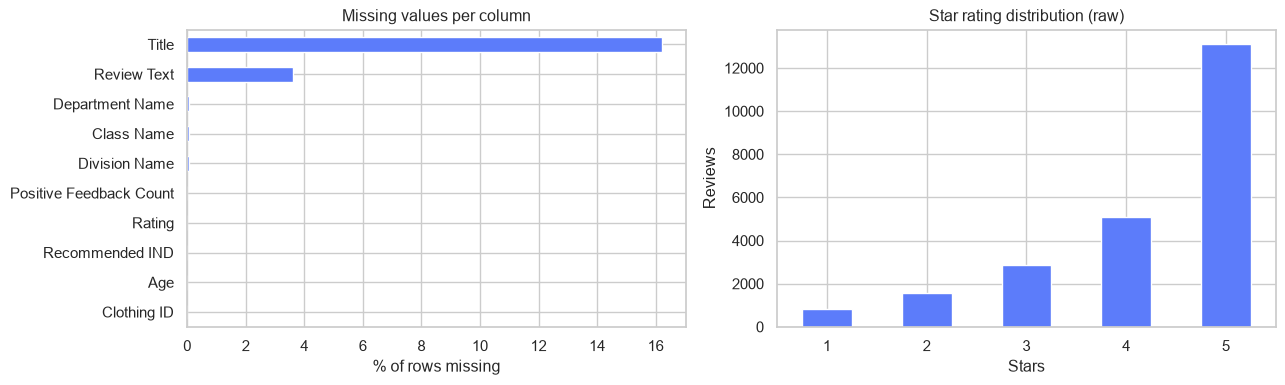

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
missing = raw.isna().mean().sort_values() * 100
missing.plot.barh(ax=axes[0], color="#5c7cfa")
axes[0].set(title="Missing values per column", xlabel="% of rows missing")

raw["Rating"].value_counts().sort_index().plot.bar(ax=axes[1], color="#5c7cfa", rot=0)
axes[1].set(title="Star rating distribution (raw)", xlabel="Stars", ylabel="Reviews")
plt.tight_layout(); plt.show()

About 3.6% of reviews have **no text**, so they can't be used for text classification. Ratings skew heavily towards 5 stars.

## 2. Clean the data and derive sentiment labels
Rules: drop empty or whitespace-only reviews, drop exact duplicates, keep ratings 1–5. Labels come from the stars: **1–2 → negative, 3 → neutral, 4–5 → positive**. The model's input text is the title plus the review.

In [5]:
df, quality = clean_data(raw)
steps = pd.DataFrame({
    "step": ["raw", "after dropping empty text", "after dropping duplicates", "after rating check (final)"],
    "rows": [quality["initial_rows"], quality["rows_after_empty_text_filter"], quality["rows_after_dedup"], quality["final_rows"]],
})
steps["dropped"] = (-steps["rows"].diff()).fillna(0).astype(int)
steps

,step,rows,dropped
0,raw,23486,0
1,after dropping empty text,22641,845
2,after dropping duplicates,22640,1
3,after rating check (final),22640,0


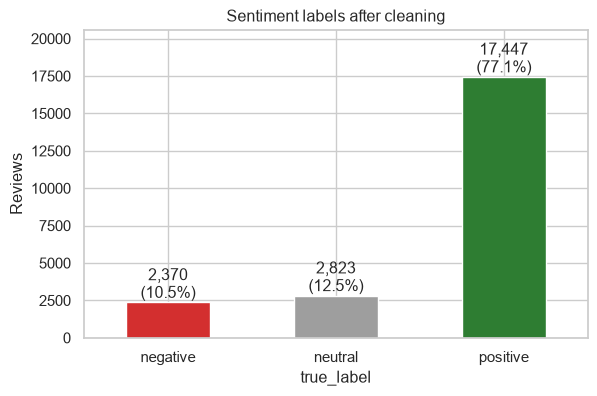

In [6]:
counts = df["true_label"].value_counts().reindex(ORDER)
ax = counts.plot.bar(color=[PALETTE[c] for c in ORDER], rot=0, figsize=(6.5, 4))
for i, v in enumerate(counts):
    ax.text(i, v, f"{v:,}\n({v / counts.sum():.1%})", ha="center", va="bottom")
ax.set(title="Sentiment labels after cleaning", ylabel="Reviews", ylim=(0, counts.max() * 1.18))
plt.show()

The classes are **imbalanced**: about 77% positive. A model that always says *positive* would already be 77% accurate, so we judge models on **macro-F1**, which weights each class equally.

## 3. Explore the data

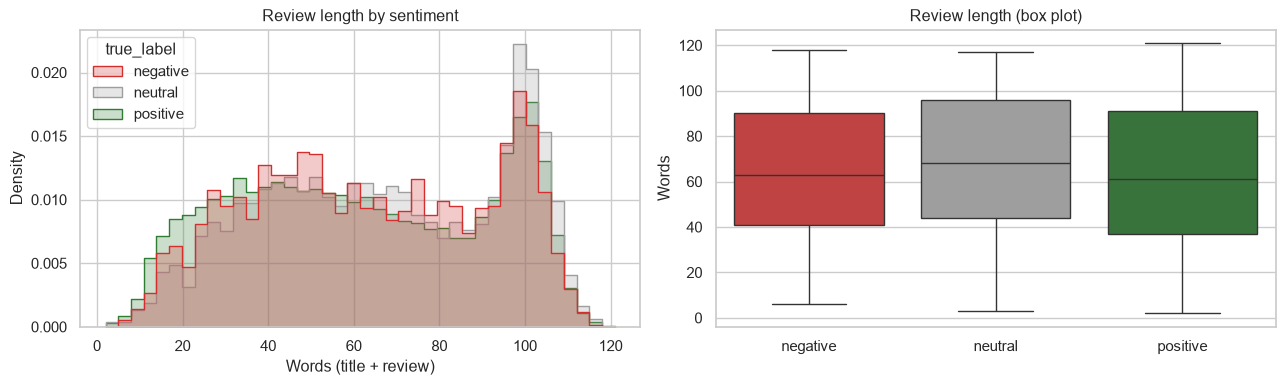

,count,mean,std,min,25%,50%,75%,max
true_label,,,,,,,,
negative,2370.0,64.0,27.7,6.0,41.0,63.0,90.0,118.0
neutral,2823.0,67.6,27.9,3.0,44.0,68.0,96.0,117.0
positive,17447.0,62.3,29.4,2.0,37.0,61.0,91.0,121.0


In [7]:
df["Department Name"] = df["Department Name"].fillna("Unknown")
df["words"] = df["input_text"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x="words", hue="true_label", hue_order=ORDER, palette=PALETTE,
             stat="density", common_norm=False, element="step", bins=40, ax=axes[0])
axes[0].set(title="Review length by sentiment", xlabel="Words (title + review)")
sns.boxplot(data=df, x="true_label", y="words", order=ORDER, palette=PALETTE, ax=axes[1])
axes[1].set(title="Review length (box plot)", xlabel="", ylabel="Words")
plt.tight_layout(); plt.show()
df.groupby("true_label")["words"].describe().reindex(ORDER).round(1)

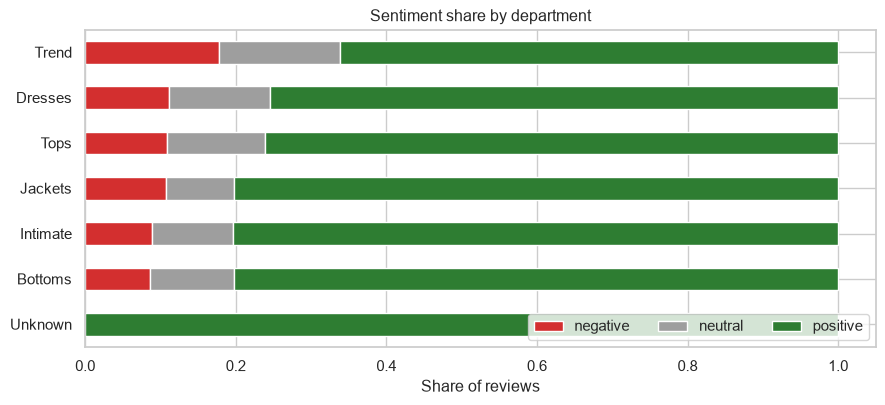

In [8]:
share = pd.crosstab(df["Department Name"], df["true_label"], normalize="index")[ORDER]
share = share.sort_values("negative")
ax = share.plot.barh(stacked=True, color=[PALETTE[c] for c in ORDER], figsize=(9, 4.2))
ax.set(title="Sentiment share by department", xlabel="Share of reviews", ylabel="")
ax.legend(title="", loc="lower right", ncols=3)
plt.tight_layout(); plt.show()

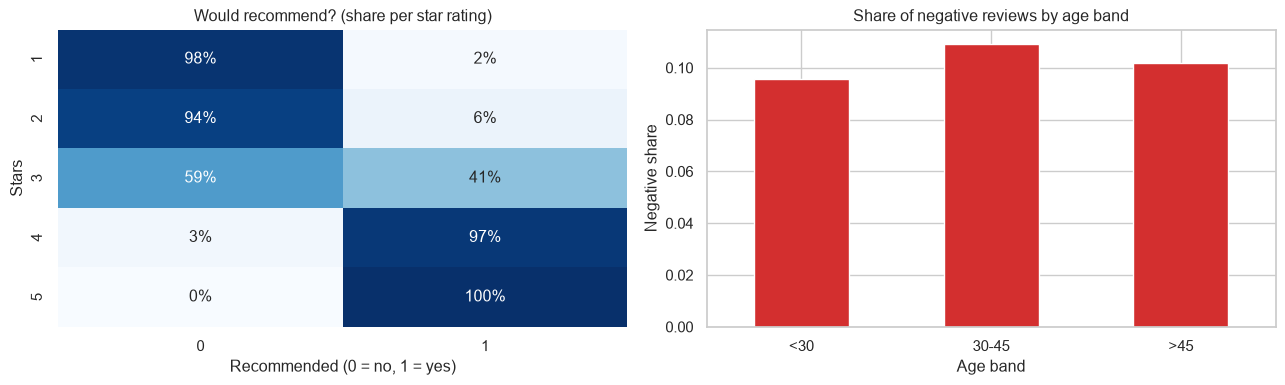

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
rec = pd.crosstab(df["Rating"], df["Recommended IND"], normalize="index")
sns.heatmap(rec, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=axes[0])
axes[0].set(title="Would recommend? (share per star rating)", xlabel="Recommended (0 = no, 1 = yes)", ylabel="Stars")

df["age_band"] = pd.cut(df["Age"], bins=[0, 29, 45, 120], labels=["<30", "30-45", ">45"])
neg_by_age = df.groupby("age_band", observed=True)["true_label"].apply(lambda s: (s == "negative").mean())
neg_by_age.plot.bar(ax=axes[1], color=PALETTE["negative"], rot=0)
axes[1].set(title="Share of negative reviews by age band", xlabel="Age band", ylabel="Negative share")
plt.tight_layout(); plt.show()

Negative reviews are slightly **longer** (customers explain what went wrong), the **Trend** department has the most negative feedback, and 3-star reviewers are split on whether they'd recommend the product. That split is a first hint that *neutral* is a mixed class.

## 4. Text preprocessing (NLP)
`TextPreprocessor` lowercases; strips URLs, HTML, digits and punctuation; tokenises with NLTK; removes stop words **but keeps negations**; and lemmatises (*dresses → dress*). Contractions such as *didn't* and *dont* become *not*, so "didn't like" isn't reduced to "like".

In [10]:
pre = TextPreprocessor()
examples = [
    "I didn't like the fabric and it doesn't fit!!",
    "Love these dresses <br> 5 stars, see http://shop.example.com",
    "Runs small... ordered a size 4 but needed a 6. Not returning it though",
    "I dont think the colors match the photos",
]
pd.DataFrame({"original": examples, "cleaned": pre.transform(examples)})

,original,cleaned
0,I didn't like the fabric and it doesn't fit!!,not like fabric not fit
1,"Love these dresses <br> 5 stars, see http://shop.example.com",love dress star see
2,Runs small... ordered a size 4 but needed a 6. Not returning it though,run small ordered size needed not returning though
3,I dont think the colors match the photos,not think color match photo


In [11]:
%%time
df["clean"] = pre.transform(df["input_text"])
df[["input_text", "clean", "true_label"]].head(5)

CPU times: total: 23.3 s
Wall time: 27 s


,input_text,clean,true_label
0,Absolutely wonderful - silky and sexy and comfortable,absolutely wonderful silky sexy comfortable,positive
1,"Love this dress! it's sooo pretty. i happened to find it in a store, and i'm glad i did bc i never would have ordered it online bc it's ...",love dress sooo pretty happened find store glad bc never would ordered online bc petite bought petite love length hit little knee would ...,positive
2,Some major design flaws I had such high hopes for this dress and really wanted it to work for me. i initially ordered the petite small (...,major design flaw high hope dress really wanted work initially ordered petite small usual size found outrageously small small fact could...,neutral
3,"My favorite buy! I love, love, love this jumpsuit. it's fun, flirty, and fabulous! every time i wear it, i get nothing but great complim...",favorite buy love love love jumpsuit fun flirty fabulous every time wear get nothing great compliment,positive
4,Flattering shirt This shirt is very flattering to all due to the adjustable front tie. it is the perfect length to wear with leggings an...,flattering shirt shirt flattering due adjustable front tie perfect length wear legging sleeveless pair well cardigan love shirt,positive


## 5. Bag-of-words and TF-IDF, step by step
A model can't read text, so each review becomes a vector of numbers. **Bag-of-words** counts how often each word (or word pair, a *bigram*) appears and ignores word order. Here it is on four tiny reviews:

In [12]:
toy = ["love this dress", "dress run small", "not love fabric", "love love fabric soft"]
bow_toy = CountVectorizer()
dtm = bow_toy.fit_transform(toy)
pd.DataFrame(dtm.toarray(), columns=bow_toy.get_feature_names_out(), index=[f"review {i + 1}" for i in range(len(toy))])

,dress,fabric,love,not,run,small,soft,this
review 1,1,0,1,0,0,0,0,1
review 2,1,0,0,0,1,1,0,0
review 3,0,1,1,1,0,0,0,0
review 4,0,1,2,0,0,0,1,0


Each **row** is a review and each **column** a vocabulary word; the cells are counts. Adding **bigrams** captures short phrases such as *not love*, which a single-word bag would split into *not* and *love*:

In [13]:
bow2 = CountVectorizer(ngram_range=(1, 2))
dtm2 = bow2.fit_transform(toy)
pd.DataFrame(dtm2.toarray(), columns=bow2.get_feature_names_out(), index=[f"review {i + 1}" for i in range(len(toy))])

,dress,dress run,fabric,fabric soft,love,love fabric,love love,love this,not,not love,run,run small,small,soft,this,this dress
review 1,1,0,0,0,1,0,0,1,0,0,0,0,0,0,1,1
review 2,1,1,0,0,0,0,0,0,0,0,1,1,1,0,0,0
review 3,0,0,1,0,1,1,0,0,1,1,0,0,0,0,0,0
review 4,0,0,1,1,2,1,1,0,0,0,0,0,0,1,0,0


**TF-IDF** rescales the counts: words that appear in many reviews (like *love* here) are down-weighted, and rarer, more specific words are boosted.

In [14]:
tfidf_toy = TfidfVectorizer()
pd.DataFrame(tfidf_toy.fit_transform(toy).toarray().round(2), columns=tfidf_toy.get_feature_names_out(),
             index=[f"review {i + 1}" for i in range(len(toy))])

,dress,fabric,love,not,run,small,soft,this
review 1,0.55,0.00,0.45,0.0,0.00,0.00,0.00,0.7
review 2,0.49,0.00,0.00,0.0,0.62,0.62,0.00,0.0
review 3,0.00,0.55,0.45,0.7,0.00,0.00,0.00,0.0
review 4,0.00,0.44,0.71,0.0,0.00,0.00,0.55,0.0


On the real reviews, the matrix is large and almost entirely zeros (*sparse*):

Document-term matrix: 22,640 reviews x 47,614 terms
Non-zero cells: 1,041,369 (0.097% of the matrix); the rest are zeros


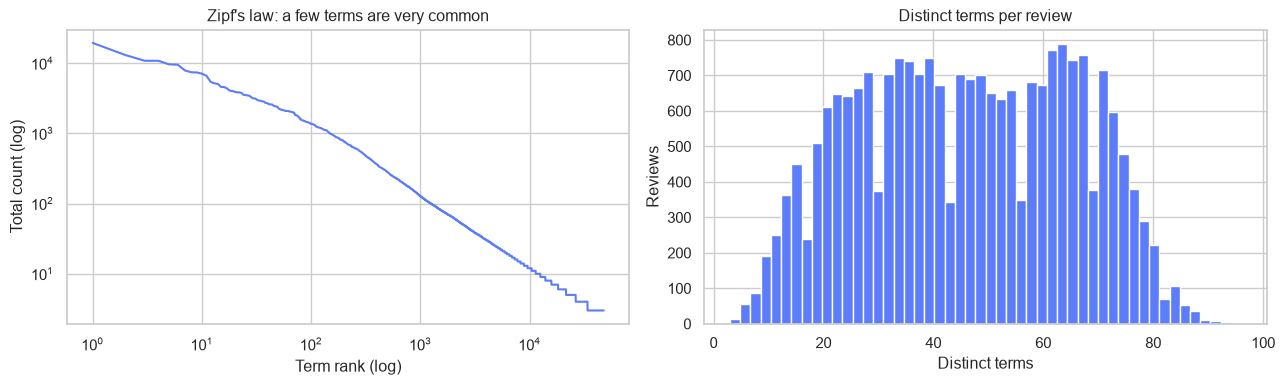

In [15]:
bow_full = CountVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000)
X_all = bow_full.fit_transform(df["clean"])
density = X_all.nnz / (X_all.shape[0] * X_all.shape[1])
print(f"Document-term matrix: {X_all.shape[0]:,} reviews x {X_all.shape[1]:,} terms")
print(f"Non-zero cells: {X_all.nnz:,} ({density:.3%} of the matrix); the rest are zeros")

freq = np.asarray(X_all.sum(axis=0)).ravel()
ranked = np.sort(freq)[::-1]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].loglog(np.arange(1, len(ranked) + 1), ranked, color="#5c7cfa")
axes[0].set(title="Zipf's law: a few terms are very common", xlabel="Term rank (log)", ylabel="Total count (log)")
n_words = np.asarray((X_all > 0).sum(axis=1)).ravel()
axes[1].hist(n_words, bins=50, color="#5c7cfa")
axes[1].set(title="Distinct terms per review", xlabel="Distinct terms", ylabel="Reviews")
plt.tight_layout(); plt.show()

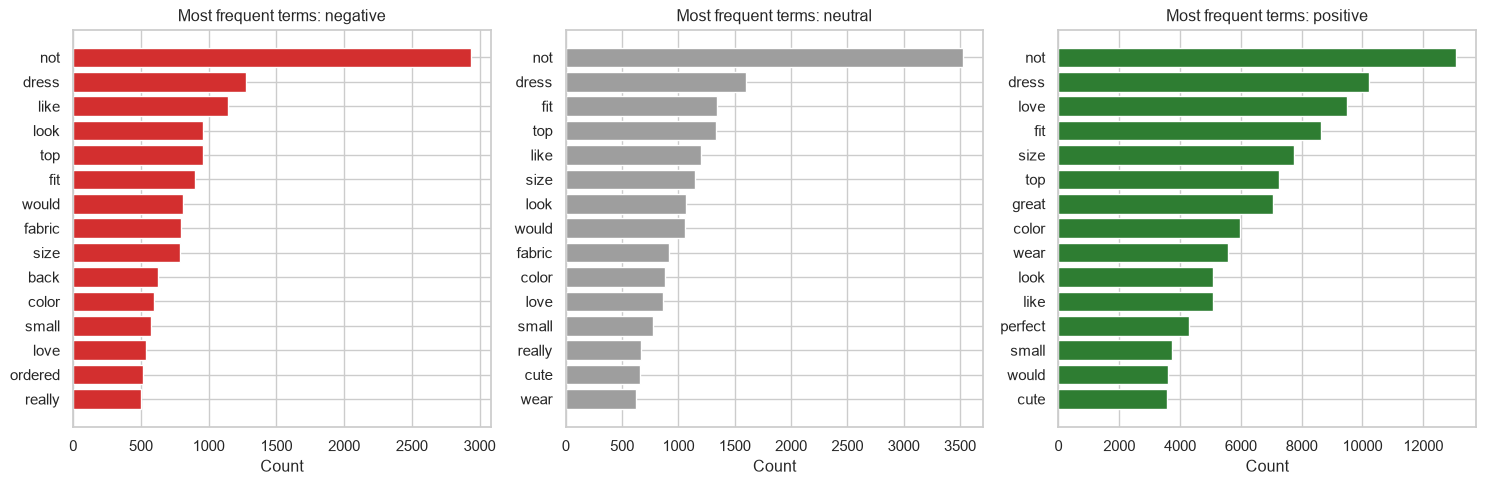

In [16]:
terms = bow_full.get_feature_names_out()
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, label in zip(axes, ORDER):
    rows = (df["true_label"] == label).to_numpy()
    counts = np.asarray(X_all[rows].sum(axis=0)).ravel()
    top = counts.argsort()[::-1][:15]
    ax.barh(terms[top][::-1], counts[top][::-1], color=PALETTE[label])
    ax.set(title=f"Most frequent terms: {label}", xlabel="Count")
plt.tight_layout(); plt.show()

Raw frequencies are dominated by words common to every class (*dress*, *fit*, *size*). The model needs words that **distinguish** classes; we'll see those in section 11.

## 6. Train / validation / test split
A **stratified** 70 / 15 / 15 split keeps the label mix identical in every part. The model is fit on *train*, compared and tuned on *validation*, and scored **once** on *test*.

In [17]:
df_split, _ = make_stratified_split(df, save_path=Path(tempfile.mkdtemp()) / "split_ids.json")
train, val, test = (df_split[df_split["split"] == s] for s in ("train", "val", "test"))
X_train, y_train = train["clean"], train["true_label"]
X_val, y_val = val["clean"], val["true_label"]
X_test, y_test = test["clean"], test["true_label"]
print(f"train {len(train):,} | validation {len(val):,} | test {len(test):,}")
pd.crosstab(df_split["split"], df_split["true_label"], normalize="index").reindex(["train", "val", "test"])[ORDER].round(3)

train 15,848 | validation 3,396 | test 3,396


true_label,negative,neutral,positive
split,,,
train,0.105,0.125,0.771
val,0.105,0.125,0.771
test,0.105,0.125,0.771


## 7. Baseline: Multinomial Naive Bayes on bag-of-words
Naive Bayes is the classic text baseline: fast and surprisingly strong. All models are scikit-learn **Pipelines** (vectoriser → classifier), so the vocabulary is learned from training data only.

accuracy       0.8363
macro_f1       0.6513
negative_f1    0.5614
neutral_f1     0.4605
positive_f1    0.9320


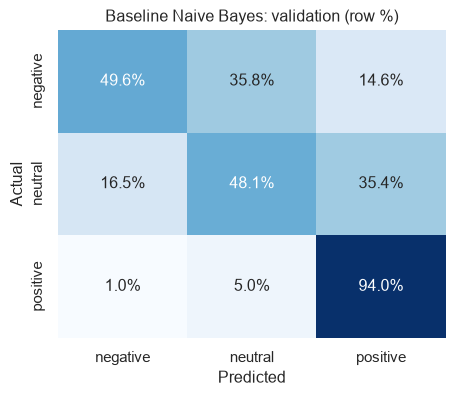

In [18]:
def bow():
    return CountVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000)

def tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True, max_features=50000)

def scores(model, X, y):
    m = compute_metrics(y, model.predict(X))
    return {"accuracy": m["accuracy"], "macro_f1": m["macro_f1"],
            **{f"{c}_f1": m["per_class"][c]["f1"] for c in ORDER}}

def plot_confusion(y_true, y_pred, title, ax=None):
    cm = confusion_matrix(y_true, y_pred, labels=ORDER, normalize="true")
    ax = ax or plt.subplots(figsize=(5, 4))[1]
    sns.heatmap(cm, annot=True, fmt=".1%", cmap="Blues", cbar=False, xticklabels=ORDER, yticklabels=ORDER, ax=ax)
    ax.set(title=title, xlabel="Predicted", ylabel="Actual")
    return ax

baseline = Pipeline([("vectorizer", bow()), ("classifier", MultinomialNB())]).fit(X_train, y_train)
print(pd.Series(scores(baseline, X_val, y_val)).round(4).to_string())
plot_confusion(y_val, baseline.predict(X_val), "Baseline Naive Bayes: validation (row %)")
plt.show()

## 8. Compare models
Logistic Regression and Random Forest use `class_weight="balanced"` to counter the imbalance. Every model is scored on the **validation** set.

In [19]:
%%time
candidates = {
    "Naive Bayes (BoW)": Pipeline([("vectorizer", bow()), ("classifier", MultinomialNB())]),
    "Naive Bayes (TF-IDF)": Pipeline([("vectorizer", tfidf()), ("classifier", MultinomialNB())]),
    "Logistic Regression (TF-IDF)": Pipeline([("vectorizer", tfidf()), ("classifier", LogisticRegression(
        class_weight="balanced", max_iter=2000, random_state=SEED))]),
    "Random Forest (TF-IDF)": Pipeline([("vectorizer", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=20000)),
                                        ("classifier", RandomForestClassifier(n_estimators=150, class_weight="balanced",
                                                                              n_jobs=-1, random_state=SEED))]),
}
results = pd.DataFrame({name: scores(model.fit(X_train, y_train), X_val, y_val) for name, model in candidates.items()}).T
results.sort_values("macro_f1", ascending=False).round(4)

CPU times: total: 1min 8s
Wall time: 22.8 s


,accuracy,macro_f1,negative_f1,neutral_f1,positive_f1
Naive Bayes (BoW),0.8363,0.6513,0.5614,0.4605,0.9320
Logistic Regression (TF-IDF),0.8171,0.6424,0.5602,0.4428,0.9242
Random Forest (TF-IDF),0.8236,0.5773,0.5371,0.2758,0.9190
Naive Bayes (TF-IDF),0.7721,0.2994,0.0223,0.0047,0.8713


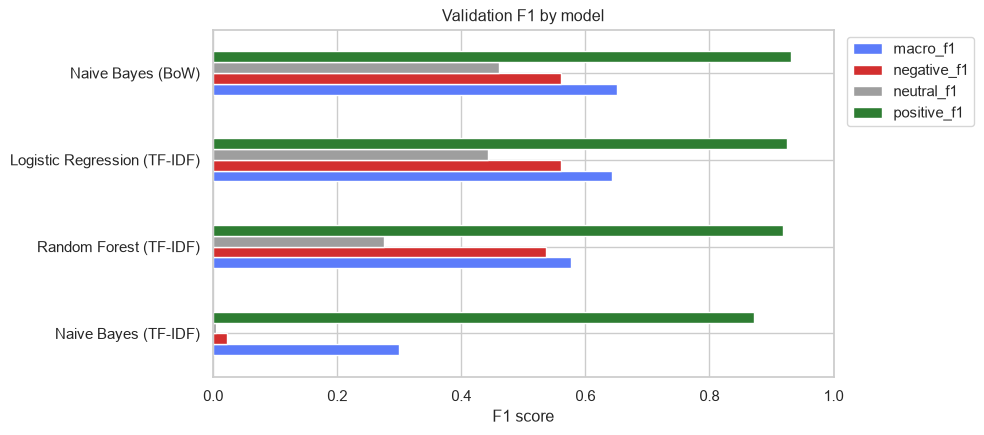

In [20]:
ax = results[["macro_f1", "negative_f1", "neutral_f1", "positive_f1"]].sort_values("macro_f1").plot.barh(
    figsize=(10, 4.5), color=["#5c7cfa", PALETTE["negative"], PALETTE["neutral"], PALETTE["positive"]])
ax.set(title="Validation F1 by model", xlabel="F1 score", xlim=(0, 1))
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

Linear models on word counts beat the Random Forest: tens of thousands of sparse n-gram features suit them far better than trees. In every model, **neutral** is the weakest class.

## 9. Hyperparameter tuning
`GridSearchCV` with stratified 5-fold cross-validation on the **training** set searches Naive Bayes smoothing (`alpha`) and n-gram range, scored by macro-F1.

Best parameters: {'classifier__alpha': 0.5, 'vectorizer__ngram_range': (1, 2)} | CV macro-F1: 0.6494


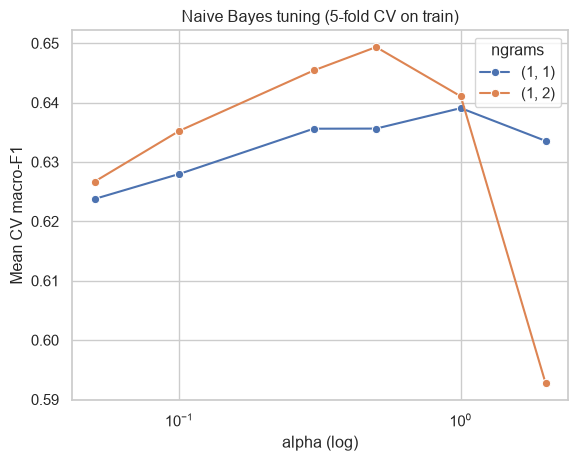

CPU times: total: 5.98 s
Wall time: 56.8 s


In [21]:
%%time
grid = GridSearchCV(
    Pipeline([("vectorizer", CountVectorizer(min_df=3, max_features=50000)), ("classifier", MultinomialNB())]),
    {"vectorizer__ngram_range": [(1, 1), (1, 2)], "classifier__alpha": [0.05, 0.1, 0.3, 0.5, 1.0, 2.0]},
    scoring="f1_macro", cv=StratifiedKFold(5, shuffle=True, random_state=SEED), n_jobs=-1,
).fit(X_train, y_train)
print("Best parameters:", grid.best_params_, "| CV macro-F1:", round(grid.best_score_, 4))

cv = pd.DataFrame(grid.cv_results_)
cv["ngrams"] = cv["param_vectorizer__ngram_range"].astype(str)
ax = sns.lineplot(data=cv, x="param_classifier__alpha", y="mean_test_score", hue="ngrams", marker="o")
ax.set(xscale="log", title="Naive Bayes tuning (5-fold CV on train)", xlabel="alpha (log)", ylabel="Mean CV macro-F1")
plt.show()

In [22]:
tuned = grid.best_estimator_
results.loc["Tuned Naive Bayes"] = scores(tuned, X_val, y_val)
best_name = results["macro_f1"].idxmax()
final_model = tuned if best_name == "Tuned Naive Bayes" else candidates[best_name]
print("Selected on validation macro-F1:", best_name)
results.sort_values("macro_f1", ascending=False).round(4)

Selected on validation macro-F1: Tuned Naive Bayes


,accuracy,macro_f1,negative_f1,neutral_f1,positive_f1
Tuned Naive Bayes,0.8313,0.6595,0.5786,0.4702,0.9297
Naive Bayes (BoW),0.8363,0.6513,0.5614,0.4605,0.9320
Logistic Regression (TF-IDF),0.8171,0.6424,0.5602,0.4428,0.9242
Random Forest (TF-IDF),0.8236,0.5773,0.5371,0.2758,0.9190
Naive Bayes (TF-IDF),0.7721,0.2994,0.0223,0.0047,0.8713


## 10. Final evaluation on the held-out test set
The test set is used **once**, for the selected model only.

              precision    recall  f1-score   support

    negative      0.576     0.604     0.590       356
     neutral      0.430     0.501     0.463       423
    positive      0.944     0.912     0.928      2617

    accuracy                          0.829      3396
   macro avg      0.650     0.673     0.660      3396
weighted avg      0.841     0.829     0.835      3396



Test macro-F1 0.6602 vs baseline 0.6537  (acceptance gate: >= 0.65 and beats baseline)


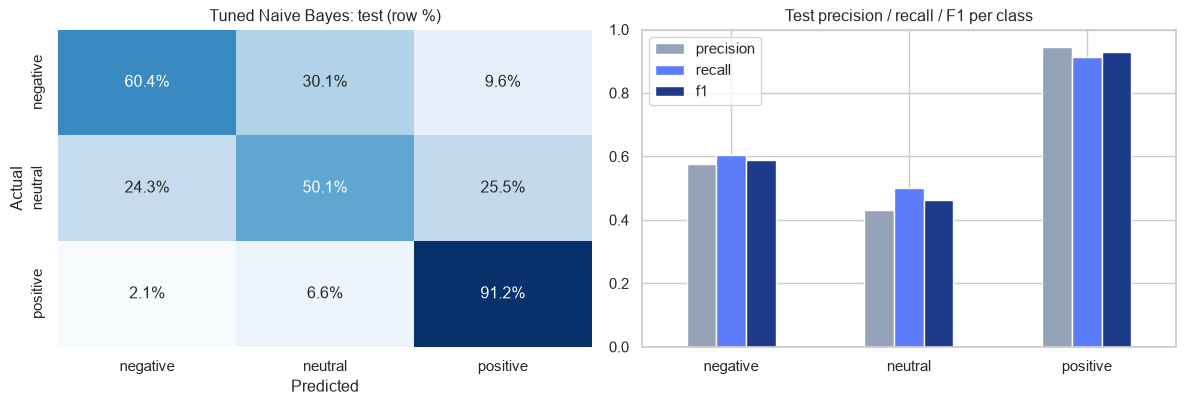

In [23]:
test_pred = final_model.predict(X_test)
print(classification_report(y_test, test_pred, labels=ORDER, digits=3))
test_scores = compute_metrics(y_test, test_pred)
base_scores = compute_metrics(y_test, baseline.predict(X_test))
print(f"Test macro-F1 {test_scores['macro_f1']:.4f} vs baseline {base_scores['macro_f1']:.4f}  (acceptance gate: >= 0.65 and beats baseline)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
plot_confusion(y_test, test_pred, f"{best_name}: test (row %)", ax=axes[0])
per_class = pd.DataFrame(test_scores["per_class"]).T.loc[ORDER, ["precision", "recall", "f1"]]
per_class.plot.bar(ax=axes[1], rot=0, color=["#94a3b8", "#5c7cfa", "#1e3a8a"])
axes[1].set(title="Test precision / recall / F1 per class", ylim=(0, 1))
plt.tight_layout(); plt.show()

## 11. What the model learned
For Naive Bayes, a term's *log-probability* under one class minus its average over all classes shows how strongly it points to that class. Unlike raw frequency (section 5), this surfaces **distinctive** phrases.

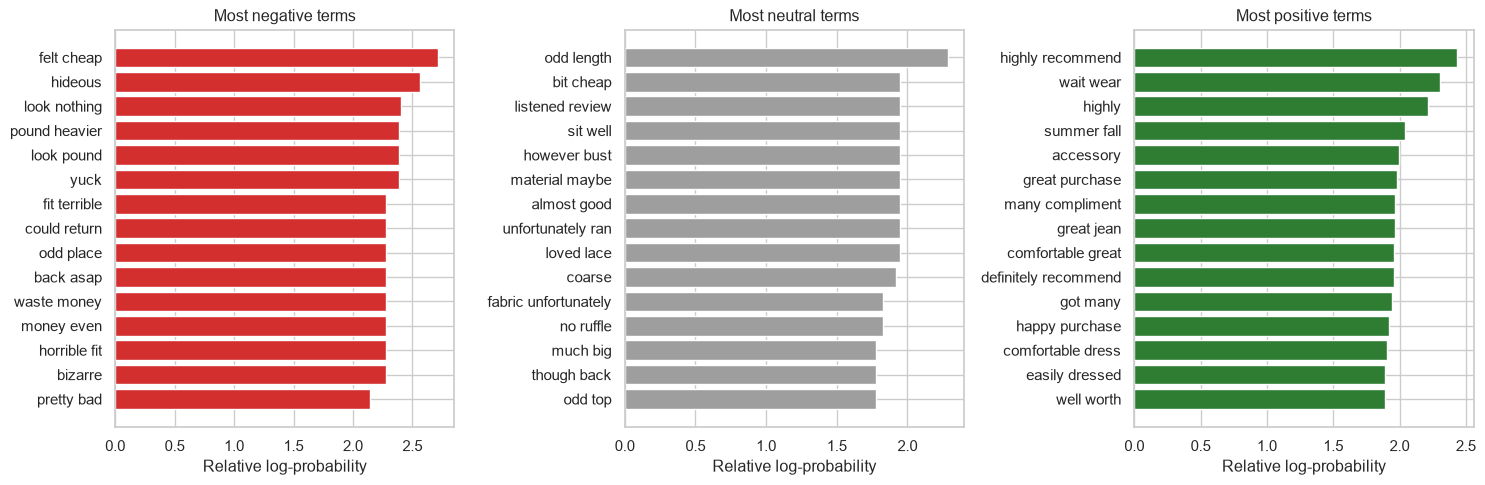

In [24]:
vec, clf = final_model.named_steps["vectorizer"], final_model.named_steps["classifier"]
names = vec.get_feature_names_out()
if hasattr(clf, "feature_log_prob_"):
    weights = clf.feature_log_prob_ - clf.feature_log_prob_.mean(axis=0)
elif hasattr(clf, "coef_"):
    weights = clf.coef_
else:
    weights = None

if weights is not None:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    for ax, (i, label) in zip(axes, enumerate(clf.classes_)):
        top = weights[i].argsort()[::-1][:15]
        ax.barh(names[top][::-1], weights[i][top][::-1], color=PALETTE[label])
        ax.set(title=f"Most {label} terms", xlabel="Relative log-probability")
    plt.tight_layout(); plt.show()

## 12. Error analysis

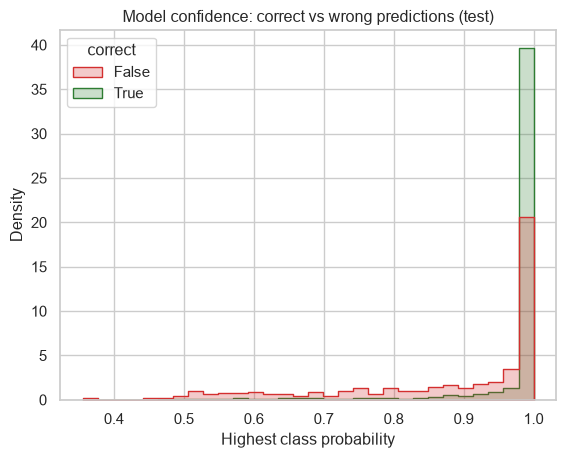

Most confident mistakes:


,Rating,true_label,predicted,confidence,input_text
19511,3,neutral,positive,1.0,Dry clean only! I saw this in my local retailer store and thought it was super cute. tried it on and was delighted. the top fits nice an...
2998,3,neutral,negative,1.0,Do not wash Ok so when i bought this in every color there were no negative reviews. i loved this shirt. it was amazing. fit perfect was ...
18246,3,neutral,positive,1.0,Pretty... Probably should have returned this but it's just so pretty. i got complements from strangers the very first time i wore it but...
5510,3,neutral,positive,1.0,"Pretty and comfrotable, get on sale I feel the same way about this shirt as i do about the sungarden tee. it's a lovely pattern and i li..."
10704,2,negative,positive,1.0,Buyer beware- stretches out significantly! I am obsessed with denim and have two other pairs of ag jeans from retailer that i am very ha...
10517,1,negative,positive,1.0,Beautiful dress; so excited to wear it!!! I saw this dress in the catalog and had to have it. when i went to the store it was sold out s...
14835,3,neutral,positive,1.0,Warm & heavy sweater This sweater runs true to size. i am 5'7' and 125 lbs and ordered the small. it has a beautiful mix of colors that ...
21779,3,neutral,positive,1.0,A good staple in a wardrobe This is a very comfortable shirt great basic to have in the wardrobe it runs a little high on the sides


In [25]:
proba = final_model.predict_proba(X_test)
errors = test.assign(predicted=test_pred, confidence=proba.max(axis=1))
errors["correct"] = errors["predicted"] == errors["true_label"]

ax = sns.histplot(data=errors, x="confidence", hue="correct", bins=30, stat="density", common_norm=False,
                  palette={True: "#2e7d32", False: "#d32f2f"}, element="step")
ax.set(title="Model confidence: correct vs wrong predictions (test)", xlabel="Highest class probability")
plt.show()

print("Most confident mistakes:")
errors.loc[~errors["correct"]].sort_values("confidence", ascending=False)[
    ["Rating", "true_label", "predicted", "confidence", "input_text"]].head(8).round(3)

Wrong predictions mostly have **lower confidence**, which is useful in practice: low-confidence predictions can be routed to a person. Many confident mistakes are reviews whose star rating disagrees with their wording.

## 13. Why the neutral class is hard
3-star reviews usually **mix praise and complaints**, so their words overlap with both neighbouring classes.

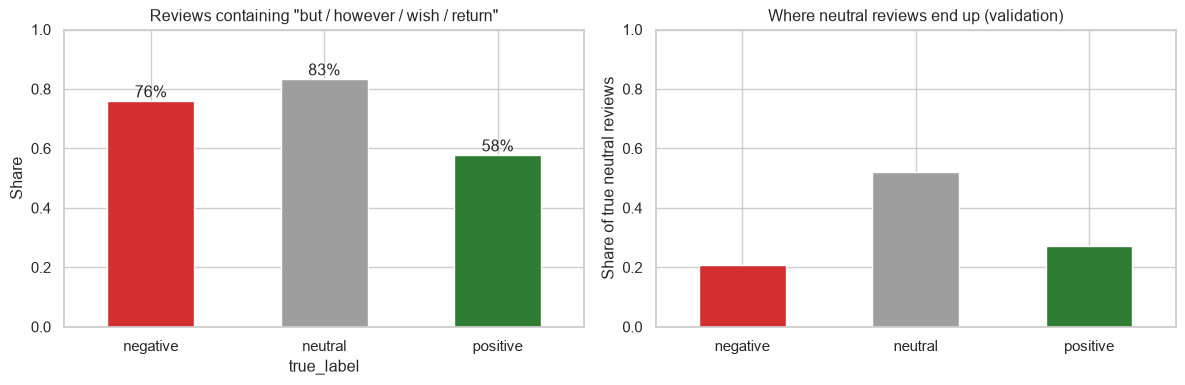

In [26]:
contrast = r"\b(?:but|however|though|although|unfortunately|wish|returned|return)\b"
mixed = df.assign(mixed=df["input_text"].str.contains(contrast, case=False, regex=True)).groupby("true_label")["mixed"].mean().reindex(ORDER)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
mixed.plot.bar(ax=axes[0], color=[PALETTE[c] for c in ORDER], rot=0)
for i, v in enumerate(mixed):
    axes[0].text(i, v, f"{v:.0%}", ha="center", va="bottom")
axes[0].set(title='Reviews containing "but / however / wish / return"', ylabel="Share", ylim=(0, 1))

neutral_rows = (y_val == "neutral").to_numpy()
where = pd.Series(final_model.predict(X_val[neutral_rows])).value_counts(normalize=True).reindex(ORDER).fillna(0)
where.plot.bar(ax=axes[1], color=[PALETTE[c] for c in ORDER], rot=0)
axes[1].set(title="Where neutral reviews end up (validation)", ylabel="Share of true neutral reviews", ylim=(0, 1))
plt.tight_layout(); plt.show()

Several approaches to improving neutral were tested during the project (all tuned on training data and scored on validation):

| Approach | Validation neutral F1 | Validation macro-F1 |
|---|---|---|
| Tuned Naive Bayes (production) | 0.470 | 0.660 |
| Naive Bayes with a uniform class prior | 0.472 | 0.658 |
| Complement Naive Bayes | 0.42–0.43 | 0.63–0.64 |
| Logistic Regression, word / word+character n-grams | 0.44–0.45 | 0.64–0.65 |
| Train on 5 star levels, then merge to 3 | 0.40–0.47 | 0.62–0.65 |
| Predict the star rating with regression, tuned cut-points | 0.41–0.45 | 0.63–0.64 |
| Ordinal model (two yes/no classifiers) | 0.22–0.44 | 0.59–0.65 |
| Average of Naive Bayes + Logistic Regression, tuned class weights | **0.478** | **0.664** |

Nothing beat the production model by more than noise (about 1 point on 424 neutral reviews). Word-count models have hit their ceiling here; a real improvement would need a model that understands sentence meaning, such as pretrained sentence embeddings.

In [27]:
# Quick live check of two of those ideas on validation
uniform = Pipeline([("vectorizer", bow()), ("classifier", MultinomialNB(alpha=0.5, fit_prior=False))]).fit(X_train, y_train)
lr = candidates["Logistic Regression (TF-IDF)"]
avg_pred = np.array(tuned.classes_)[np.argmax((tuned.predict_proba(X_val) + lr.predict_proba(X_val)) / 2, axis=1)]
pd.DataFrame({
    "Tuned Naive Bayes": scores(tuned, X_val, y_val),
    "Naive Bayes, uniform prior": scores(uniform, X_val, y_val),
    "Average NB + LR": {"accuracy": (avg_pred == y_val).mean(), "macro_f1": f1_score(y_val, avg_pred, average="macro"),
                        **dict(zip([f"{c}_f1" for c in ORDER], f1_score(y_val, avg_pred, labels=ORDER, average=None)))},
}).T.round(4)

,accuracy,macro_f1,negative_f1,neutral_f1,positive_f1
Tuned Naive Bayes,0.8313,0.6595,0.5786,0.4702,0.9297
"Naive Bayes, uniform prior",0.8183,0.6577,0.5800,0.4717,0.9214
Average NB + LR,0.8310,0.6598,0.5806,0.4691,0.9296


## 14. Fairness across departments and age groups
Macro-F1 on the test set for each subgroup with at least 30 reviews. The project flags any group more than 10 points from the overall score.

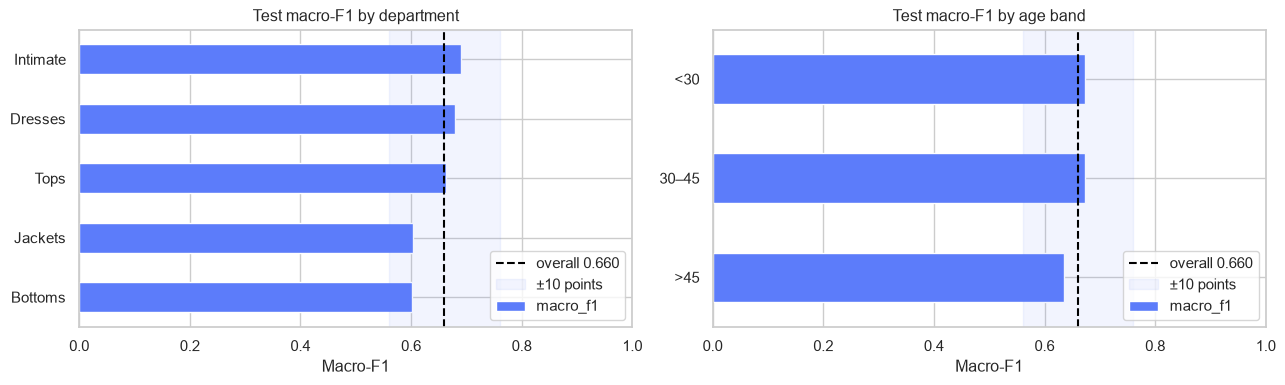

Flagged groups: none


In [28]:
fair = run_ethics_evaluation(test, y_test.tolist(), list(test_pred))
dept = pd.DataFrame(fair["department_metrics"]).T
age = pd.DataFrame(fair["age_band_metrics"]).T

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, frame, title in [(axes[0], dept, "By department"), (axes[1], age, "By age band")]:
    frame["macro_f1"].astype(float).sort_values().plot.barh(ax=ax, color="#5c7cfa")
    ax.axvline(fair["overall_macro_f1"], color="black", ls="--", label=f"overall {fair['overall_macro_f1']:.3f}")
    ax.axvspan(fair["overall_macro_f1"] - 0.10, fair["overall_macro_f1"] + 0.10, color="#5c7cfa", alpha=0.08, label="±10 points")
    ax.set(title=f"Test macro-F1 {title.lower()}", xlabel="Macro-F1", xlim=(0, 1))
    ax.legend(loc="lower right")
plt.tight_layout(); plt.show()
print("Flagged groups:", fair["disparities"] or "none")

## 15. Complaint themes with clustering (unsupervised)
K-Means groups the **negative** reviews by their TF-IDF vectors; the silhouette score picks the number of clusters, and each cluster's top terms name the theme.

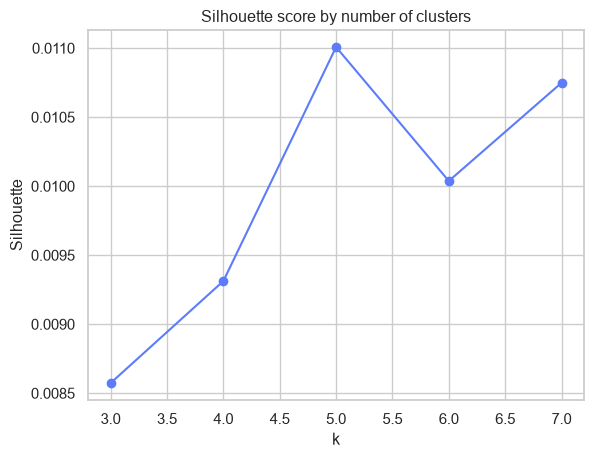

CPU times: total: 4.11 s
Wall time: 3.39 s


,reviews,top terms
theme 1,161,"sweater, like, fit, color, looks, itchy, look, looked, ordered, beautiful"
theme 2,202,"shirt, boxy, like, cute, fit, fabric, love, look, short, loved"
theme 3,441,"dress, like, just, fit, fabric, look, material, really, beautiful, size"
theme 4,642,"size, small, fit, like, ordered, short, way, large, big, runs"
theme 5,924,"fabric, like, quality, material, looks, just, love, design, great, cheap"


In [29]:
%%time
neg_text = df.loc[df["true_label"] == "negative", "input_text"]
theme_vec = TfidfVectorizer(max_features=1000, stop_words="english", min_df=2)
X_neg = theme_vec.fit_transform(neg_text)

ks, sil, models = range(3, 8), [], {}
for k in ks:
    models[k] = KMeans(n_clusters=k, random_state=SEED, n_init=5).fit(X_neg)
    sil.append(silhouette_score(X_neg, models[k].labels_))
best_k = list(ks)[int(np.argmax(sil))]

plt.plot(list(ks), sil, marker="o", color="#5c7cfa")
plt.title("Silhouette score by number of clusters"); plt.xlabel("k"); plt.ylabel("Silhouette")
plt.show()

theme_terms = theme_vec.get_feature_names_out()
centres = models[best_k].cluster_centers_.argsort(axis=1)[:, ::-1]
sizes = np.bincount(models[best_k].labels_)
pd.DataFrame({"reviews": sizes, "top terms": [", ".join(theme_terms[centres[i, :10]]) for i in range(best_k)]},
             index=[f"theme {i + 1}" for i in range(best_k)])

Silhouette scores are low (normal for short text), so treat these as starting points for an analyst. Recurring themes are **sizing**, **fabric quality** and **fit/shape**.

## 16. Using the production model
`make train` saves the selected pipeline (preprocessing → vectoriser → classifier) as one file. Loading it gives the exact model the API serves; it takes **raw** text.

In [30]:
model_path = MODELS_DIR / DEFAULT_MODEL_VERSION / "model.joblib"
production = joblib.load(model_path)
print("Loaded", model_path.relative_to(ROOT), "->", " -> ".join(production.named_steps))

samples = [
    "This dress fits like a glove and the silk fabric is breathtaking!",
    "It's okay, but it runs small and the colour is duller than pictured.",
    "Terrible quality, the seams ripped after one wash. Returning it.",
]
probs = production.predict_proba(samples)
pd.DataFrame(probs.round(3), columns=production.classes_, index=samples).assign(prediction=production.predict(samples))

Loaded models\v1.1.0\model.joblib -> preprocessor -> vect -> clf


,negative,neutral,positive,prediction
This dress fits like a glove and the silk fabric is breathtaking!,0.000,0.002,0.998,positive
"It's okay, but it runs small and the colour is duller than pictured.",0.064,0.702,0.234,neutral
"Terrible quality, the seams ripped after one wash. Returning it.",0.997,0.003,0.000,negative


## 17. Summary
- **Data:** 23,486 raw reviews → 22,640 after cleaning; heavily positive (77%), so models are judged on macro-F1.
- **Features:** bag-of-words over 1–2 word n-grams, after NLP preprocessing that keeps negations.
- **Model:** a tuned Multinomial Naive Bayes won on validation, ahead of Logistic Regression and Random Forest. On the held-out test set it clears the 0.65 macro-F1 gate and beats the untuned baseline (see section 10).
- **Strengths:** positive reviews are recognised very reliably; mistakes mostly land on the neighbouring class, and come with lower confidence.
- **Weakness:** neutral (3-star) reviews, which mix praise and complaints. Eight improvement strategies changed neutral F1 by at most about one point.
- **Fairness:** no department or age band deviates by more than 10 points from the overall score.
- **Beyond classification:** clustering surfaces complaint themes (sizing, fabric, fit) for the business.

In production, the same pipeline is served by a Flask API, batch-scores every review into SQLite, and feeds both a web dashboard and Power BI.